# T02 · Réseaux profonds : gradients & sur-apprentissage — DL/RL appliqués à la cybersécurité

**Objectifs du cours :**
- Comprendre ce que « profond » change : paramètres, mémoire, chaînes de Jacobien
- **Mesurer** le vanishing / exploding gradient couche par couche et savoir le corriger (init, clipping)
- Diagnostiquer le sur-apprentissage et les pathologies des données cyber : déséquilibre, bruit, drift

**Pourquoi c'est fondamental en cyber :**

| Besoin cyber | Outil |
|---|---|
| Mon IDS profond n'apprend plus — pourquoi ? | Vanishing gradients mesurés par couche (P2) |
| Entraînement stable sur de gros volumes de logs | Clipping de gradient (P3) |
| Réseau profond qui converge dès le départ | Initialisations Xavier / He (P4) |
| Ne pas livrer un faux sentiment de sécurité | Courbes train/val, capacité (P5) |
| Attaques rares, labels bruités, nouveaux botnets | Déséquilibre, bruit, drift (P6) |

**Pré-requis :** T01 (MLP numpy, backprop, gradient check). Aucune librairie DL :
tout est réimplémenté en numpy.

> 💡 *Conseil étude* : dans ce notebook on ne croit rien, on **mesure** —
> normes de gradient par couche, variance des activations, écart exactitude
> train/test. reproduisez chaque chiffre avant de l'admettre.


## 📌 Bloc 0 — Environnement & imports
Installez le stack si besoin (déjà pré-installé sur Colab).
Chaque notebook contient des sorties pré-calculées : vous pouvez les relire
sans rien exécuter, ou « Run All » pour reproduire.

In [1]:
!pip install -q numpy scipy pandas matplotlib scikit-learn
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
np.set_printoptions(precision=3, suppress=True, linewidth=100)
print("numpy", np.__version__)

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

numpy 2.5.4


On réutilise le MLP numpy du T01 (avant + backward écrits à la main,
perte BCE, mini-batch, pondération par exemple et clipping optionnel).


In [2]:
class MLP:
    """Feed-forward net: hidden layers with `act`, sigmoid output, BCE loss (numpy only)."""

    def __init__(self, sizes, act="relu", init="he", seed=0):
        rng = np.random.default_rng(seed)
        self.sizes = list(sizes)
        self.act = act
        self.W, self.b = [], []
        for fan_in, fan_out in zip(sizes[:-1], sizes[1:]):
            if init == "he":
                std = np.sqrt(2.0 / fan_in)
            elif init == "xavier":
                std = np.sqrt(1.0 / fan_in)
            elif init == "naive":
                std = 1.0
            elif init == "zero":
                std = 0.0
            elif init == "big":
                std = 5.0
            else:
                raise ValueError(init)
            self.W.append(rng.normal(0.0, std, (fan_in, fan_out)) if std > 0 else np.zeros((fan_in, fan_out)))
            self.b.append(np.zeros(fan_out))

    def forward(self, X):
        self.A = [X]
        self.Z = []
        a = X
        n = len(self.W)
        for i, (W, b) in enumerate(zip(self.W, self.b)):
            z = a @ W + b
            a = self._act(z) if i < n - 1 else sigmoid(z)
            self.Z.append(z)
            self.A.append(a)
        return self.A[-1]

    def _act(self, z):
        return {"sigmoid": sigmoid, "tanh": np.tanh, "relu": relu}[self.act](z)

    def _dact(self, a):
        return {"sigmoid": d_sigmoid, "tanh": d_tanh, "relu": d_relu}[self.act](a)

    def loss(self, X, y, sample_weight=None):
        p = np.clip(self.forward(X).ravel(), 1e-12, 1.0 - 1e-12)
        per = -(y * np.log(p) + (1.0 - y) * np.log(1.0 - p))
        if sample_weight is None:
            return float(per.mean())
        return float((per * sample_weight).sum() / sample_weight.sum())

    def backward(self, X, y, sample_weight=None):
        p = self.forward(X).ravel()
        m = len(y)
        if sample_weight is None:
            sw = np.ones(m); norm = float(m)
        else:
            sw = sample_weight; norm = float(sw.sum())
        delta = ((p - y) * sw / norm)[:, None]
        dW = [None] * len(self.W); db = [None] * len(self.b)
        for i in reversed(range(len(self.W))):
            dW[i] = self.A[i].T @ delta
            db[i] = delta.sum(axis=0)
            if i > 0:
                delta = (delta @ self.W[i].T) * self._dact(self.A[i])
        return dW, db

    def grad_norms(self, X, y):
        dW, db = self.backward(X, y)
        return [float(np.linalg.norm(w)) for w in dW]

    def fit(self, X, y, lr=0.05, epochs=200, batch_size=None,
            sample_weight=None, clip=None, shuffle_seed=1234):
        m = len(y)
        rng = np.random.default_rng(shuffle_seed)
        hist = []
        for _ in range(epochs):
            hist.append(self.loss(X, y, sample_weight))
            idx = np.arange(m) if batch_size is None else rng.permutation(m)
            for s in range(0, m, batch_size or m):
                b = idx[s:s + (batch_size or m)]
                dW, db = self.backward(X[b], y[b],
                                       None if sample_weight is None else sample_weight[b])
                if clip is not None:
                    gn = np.sqrt(sum(np.sum(g * g) for g in dW + db))
                    if gn > clip:
                        scale = clip / gn
                        dW = [g * scale for g in dW]
                        db = [g * scale for g in db]
                for i in range(len(self.W)):
                    self.W[i] -= lr * dW[i]
                    self.b[i] -= lr * db[i]
        hist.append(self.loss(X, y, sample_weight))
        return np.array(hist)

    def predict(self, X):
        return (self.forward(X).ravel() >= 0.5).astype(int)


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500.0, 500.0)))

def d_sigmoid(a):
    return a * (1.0 - a)

def d_tanh(a):
    return 1.0 - a ** 2

def relu(z):
    return np.maximum(z, 0.0)

def d_relu(a):
    return (a > 0).astype(float)

def standardize(Xtr, Xte):
    mu, sd = Xtr.mean(axis=0), Xtr.std(axis=0) + 1e-9
    return (Xtr - mu) / sd, (Xte - mu) / sd

## 1 · Anatomie d'un DNN : profondeur, paramètres, mémoire

### Ce qu'on apprend
Un réseau `[d, h₁, …, h_L, 1]` contient, par couche cachée ℓ :

```
#paramètres(ℓ) = h_{ℓ−1} × h_ℓ  (poids) + h_ℓ  (biais)
```

Deux goulots d'étranglement très différents à distinguer :
- **Paramètres** (coût mémoire *permanent*, et surface d'overfitting) —
  dominés par les couches larges en entrée ;
- **Activations** (coût mémoire *par batch*, celui dont on parle en « GPU OOM »)
  — proportionnelles à `batch × largeur`. Une couche de 1024 neurones sur un
  batch de 1024 en float64 coûte `1024 × 1024 × 8 o ≈ 8 Mo` … **par couche
  sauvegardée pour le backward**.

« Peu profond mais large » vs « profond mais étroit » : à nombre de couches
près, la largeur coûte quadratiquement (`d×h`), la profondeur linéairement.

### Piège classique
Comparer deux architectures uniquement en nombre de **couches** (ou en
paramètres) sans regarder la mémoire des activations : le réseau « profond »
peut tenir en mémoire et pas le réseau « large », ou l'inverse.


In [3]:
def count_params(sizes):
    """Number of trainable parameters (weights + biases) of an MLP architecture."""
    return sum(fi * fo + fo for fi, fo in zip(sizes[:-1], sizes[1:]))

arch_demo = [60, 64, 32, 1]
print(f"Architecture {arch_demo} : {count_params(arch_demo)} paramètres")
print(f"Architecture [784,256,128,10] : {count_params([784, 256, 128, 10])} paramètres")

# Large vs étroit-profond, même entrée (40 features)
wide = [40, 1024, 1]
deep = [40, 32, 32, 32, 32, 32, 1]
print(f"large  {wide} : {count_params(wide)} params")
print(f"étroit {deep} : {count_params(deep)} params  <- ~8x moins")

# Mémoire des activations (float64, batch = 1024), 1 activation sauvegardée/couche
batch = 1024
mem_wide = batch * 1024 * 8 / 1024 ** 2            # Mo (couche cachée de 1024)
mem_deep = batch * 32 * 5 * 8 / 1024 ** 2          # Mo (5 couches de 32)
print(f"Mémoire activations float64 batch {batch} : large {mem_wide:.2f} Mo, étroit {mem_deep:.2f} Mo")

# vérif : le compte théorique == le compte réel des matrices du modèle
m = MLP([40, 64, 32, 1], init="he", seed=0)
real = sum(w.size for w in m.W) + sum(bb.size for bb in m.b)
print("compte réel des paramètres du modèle [40,64,32,1] :", real)

Architecture [60, 64, 32, 1] : 6017 paramètres
Architecture [784,256,128,10] : 235146 paramètres
large  [40, 1024, 1] : 43009 params
étroit [40, 32, 32, 32, 32, 32, 1] : 5569 params  <- ~8x moins
Mémoire activations float64 batch 1024 : large 8.00 Mo, étroit 1.25 Mo
compte réel des paramètres du modèle [40,64,32,1] : 4737


### Exercice corrigé

In [4]:
# ---- Exercice P1 : compte de paramètres d'une architecture DNN ----
assert count_params([60, 64, 32, 1]) == 6017           # 60*64+64 + 64*32+32 + 32+1
assert count_params([784, 256, 128, 10]) == 235146     # sondé
assert real == count_params([40, 64, 32, 1]) == 4737   # théorique == réel
assert count_params(wide) == 43009 and count_params(deep) == 5569
assert count_params(wide) > count_params(deep)         # la largeur coûte cher
assert mem_wide > 4 * mem_deep                         # et en mémoire aussi
print(f"Exercice P1 vérifié : 6017 / 235146 / {real} paramètres ; large {mem_wide:.2f} Mo vs étroit {mem_deep:.2f} Mo.")

Exercice P1 vérifié : 6017 / 235146 / 4737 paramètres ; large 8.00 Mo vs étroit 1.25 Mo.


## 2 · Vanishing gradients : mesure par couche

### Ce qu'on apprend
Dans le backward (T01), le signal d'erreur se propage par produits de
Jacobiens :

```
δ_{ℓ−1} = (δ_ℓ W_ℓᵀ) ⊙ φ′(z_{ℓ−1})
```

Chaque couche multiplie donc l'amplitude par ‖W_ℓᵀ‖ **et** par |φ′|. Pour la
sigmoïde, `|φ′| ≤ 0.25` **partout** : sur 8 couches cachées, l'amplitude est
au mieux multipliée par `0.25⁸ ≈ 1.5×10⁻⁵` (avant même le effet de W). Les
couches proches de l'entrée apprennent ~1000× moins vite que les dernières →
le réseau « profond » sigmoïde est un empilement de couches mortes.

**Recette de diagnostic** : après un backward, tracer `‖∇W_ℓ‖` par couche.
Si la courbe décroît de plusieurs ordres de grandeur → vanishing.

### Piège classique
Croire que « profond = mieux » : sans activation bien normalisée (ReLU/tanh)
et initialisation adaptée (P4), approfondir *dégrade* l'apprentissage des premières
couches — le modèle tout court sous-apprend silencieusement.


||∇W_ℓ|| (couche d'entrée -> couche de sortie), 8 couches cachées :
 sigmoïde : [0.    0.    0.    0.    0.    0.    0.    0.001]
 tanh     : [0.088 0.143 0.134 0.144 0.163 0.147 0.152 0.234]
 relu+He  : [0.117 0.195 0.175 0.202 0.211 0.306 0.38  0.341]
rapport ||∇W₁||/||∇W₈|| : sigmoïde 1.89e-03   relu+He 3.44e-01
-> la 1re couche sigmoïde reçoit ~182x moins de signal que relu+He.


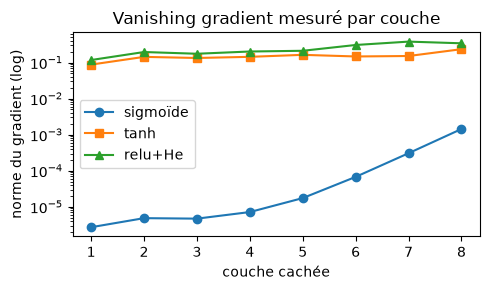

In [5]:
rng22 = np.random.default_rng(21)
X22 = rng22.normal(0, 1, (64, 20)); y22 = (X22[:, 0] > 0).astype(float)

net_sig = MLP([20, 30, 30, 30, 30, 30, 30, 30, 30, 1], act="sigmoid", init="xavier", seed=3)
gn_sig = net_sig.grad_norms(X22, y22)
net_tanh = MLP([20, 30, 30, 30, 30, 30, 30, 30, 30, 1], act="tanh", init="xavier", seed=3)
gn_tanh = net_tanh.grad_norms(X22, y22)
net_relu = MLP([20, 30, 30, 30, 30, 30, 30, 30, 30, 1], act="relu", init="he", seed=3)
gn_relu = net_relu.grad_norms(X22, y22)

print("||∇W_ℓ|| (couche d'entrée -> couche de sortie), 8 couches cachées :")
print(" sigmoïde :", np.array(gn_sig[:-1]))
print(" tanh     :", np.array(gn_tanh[:-1]))
print(" relu+He  :", np.array(gn_relu[:-1]))
ratio_sig = gn_sig[0] / gn_sig[-2]
ratio_relu = gn_relu[0] / gn_relu[-2]
print(f"rapport ||∇W₁||/||∇W₈|| : sigmoïde {ratio_sig:.2e}   relu+He {ratio_relu:.2e}")
print(f"-> la 1re couche sigmoïde reçoit ~{ratio_relu / ratio_sig:.0f}x moins de signal que relu+He.")

plt.figure(figsize=(5, 3))
ax = plt.gca()
ax.semilogy(range(1, 9), gn_sig[:-1], "o-", label="sigmoïde")
ax.semilogy(range(1, 9), gn_tanh[:-1], "s-", label="tanh")
ax.semilogy(range(1, 9), gn_relu[:-1], "^-", label="relu+He")
ax.set_xlabel("couche cachée"); ax.set_ylabel("norme du gradient (log)")
ax.set_title("Vanishing gradient mesuré par couche"); ax.legend(); plt.tight_layout(); plt.show()

### Exercice corrigé

In [6]:
# ---- Exercice P2 : effondrement des gradients sigmoïde, relu+He sain ----
assert gn_sig[0] < 1e-3                          # sondé : 2.7e-6
assert ratio_sig < 1e-2                          # sondé : 1.9e-3
assert gn_sig[0] < gn_sig[4] < gn_sig[7]         # effondrement progressif
assert gn_relu[0] > 0                            # relu+He : signal sain partout
assert ratio_relu > 50 * ratio_sig               # relu+He ≈ 180x moins vanishing
print(f"Exercice P2 vérifié : ||∇W₁|| sigmoïde = {gn_sig[0]:.1e}, ratio {ratio_sig:.1e} vs relu {ratio_relu:.2f}.")

Exercice P2 vérifié : ||∇W₁|| sigmoïde = 2.7e-06, ratio 1.9e-03 vs relu 0.34.


## 3 · Exploding gradients & clipping

### Ce qu'on apprend
Symétrique du P2 : si ‖W_ℓ‖ > 1 (mauvaise init, rétroaction RNN — cf. T05),
les gradients **explosent** et la descente saute n'importe où.

**Gradient clipping par norme globale** (l'opération que fait tout framework) :

```
g = concat(∇W₁, b₁, …, ∇W_L, b_L)
si ‖g‖ > c :  g ← g × c / ‖g‖        (on garde la DIRECTION, on borne l'amplitude)
```

Dans notre `MLP.fit(..., clip=c)` c'est exactement ce code.

### Piège classique
Le clipping **borne l'amplitude, pas la direction** : un réseau avec des poids
géants et des gradients clippés peut rester bloqué dans une région saturée.
Le clipping est un pansement ; la vraie cause est souvent l'initialisation (P4)
ou une perte mal mise à l'échelle.


In [7]:
rng22b = np.random.default_rng(21)
X22b = rng22b.normal(0, 1, (64, 20)); y22b = (X22b[:, 0] > 0).astype(float)

# Initialisation volontairement catastrophique (σ = 5)
exp_net = MLP([20, 50, 50, 1], act="relu", init="big", seed=4)
gn = exp_net.grad_norms(X22b, y22b)
g_global = float(np.sqrt(sum(g * g for g in gn)))
print("normes par couche :", gn)
print("norme globale du gradient :", g_global)

# clipping manuel, petit exemple pour la formule
gvec = [np.ones((5, 5)) * 3, np.ones(5) * 4]
g_raw = float(np.sqrt(sum(np.sum(g * g) for g in gvec)))
c = 1.0
g_after = g_raw * (c / g_raw)
print(f"exemple : ||g|| = {g_raw:.3f} -> clippé à {g_after:.3f} (seuil c = {c})")

# Sans clipping, lr = 1.0 : l'entraînement stagne (le grand pas balaie le signal).
net_nc = MLP([20, 50, 50, 1], act="relu", init="big", seed=4)
net_nc.fit(X22b, y22b, lr=1.0, epochs=60)
acc_nc = np.mean(net_nc.predict(X22b) == y22b)
net_c = MLP([20, 50, 50, 1], act="relu", init="big", seed=4)
net_c.fit(X22b, y22b, lr=1.0, epochs=60, clip=1.0)
acc_c = np.mean(net_c.predict(X22b) == y22b)
print(f"big init, lr=1.0 : sans clip exactitude {acc_nc:.3f}  |  AVEC clip=1.0 exactitude {acc_c:.3f}")

normes par couche : [233.34816340934563, 306.5923713999195, 245.09915012249303]
norme globale du gradient : 456.6441075475618
exemple : ||g|| = 17.464 -> clippé à 1.000 (seuil c = 1.0)
big init, lr=1.0 : sans clip exactitude 0.594  |  AVEC clip=1.0 exactitude 1.000


### Exercice corrigé

In [8]:
# ---- Exercice P3 : normes explosives bornées par le clipping ----
assert g_global > 1e2                            # sondé : ~457
assert abs(g_after - 1.0) < 1e-9                 # après clipping : exactement c
assert g_raw == np.sqrt(305.0)                   # sqrt(25*9 + 5*16) = sqrt(305)
assert acc_nc <= 0.70                            # sondé : 0.594 (stagne)
assert acc_c >= 0.95                             # sondé : 1.0 (clipping sauve l'entraînement)
print(f"Exercice P3 vérifié : norme brute {g_global:.0f} -> bornée à 1.0 ; acc sans clip {acc_nc:.2f}, avec clip {acc_c:.2f}.")

Exercice P3 vérifié : norme brute 457 -> bornée à 1.0 ; acc sans clip 0.59, avec clip 1.00.


## 4 · Initialisations : zéro, naive, Xavier, He

### Ce qu'on apprend
L'initialisation fixe l'échelle du signal qui traverse le réseau, **avant**
tout apprentissage.

| Init | Distribution | Pensée pour | Effet (ReLU profond, sondé P4) |
|---|---|---|---|
| zéro | `W = 0` | — | symétrie : tous les neurones identiques, jamais brisée |
| naive | `N(0, 1)` | — | explosion : std ≈ 5×10⁵ en sortie |
| Xavier | `N(0, 1/fan_in)` | tanh/sigmoïde | atténuation sous ReLU (×0.5 de variance/couche) |
| **He** | `N(0, 2/fan_in)` | **ReLU** | variance ≈ stable (std ≈ 1.6 en bout de pile) |

Pourquoi le facteur 2 pour He ? Sous ReLU, la moitié des activations sont
annulées : `E[a²] ≈ ½ var(z)`, il faut compenser par `Var(W) = 2/fan_in`.

### Piège classique
`W = 0` n'est pas « neutre » : les gradients de tous les neurones d'une même
couche sont **identiques**, les poids restent identiques pour toujours
(symétrie non brisée). Le réseau se comporte comme s'il n'avait qu'un neurone
par couche — il échoue sur XOR.


std(activation cachée)      zéro : 1re=   0.000  dernière=     0.000
std(activation cachée) naive σ=1 : 1re=   6.354  dernière=555341.779
std(activation cachée)    xavier : 1re=   1.005  dernière=     0.099
std(activation cachée)        He : 1re=   1.421  dernière=     1.589
écart max entre neurones d'une couche initialisée à zéro : 0.0
XOR : init zéro exactitude 0.50 (symétrie)  |  init He 1.00


||∇W₁|| : naive 88.5  vs He 0.567


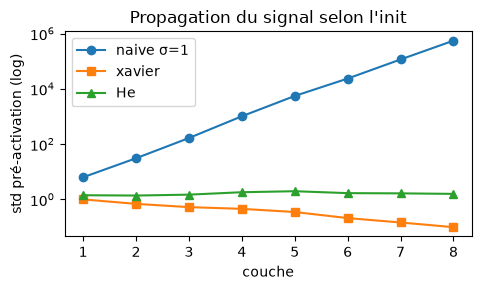

In [9]:
rng24 = np.random.default_rng(31)
Xin = rng24.normal(0, 1, (500, 40))

def signal_stats(init, act, depth=8, width=50, seed=2):
    """Std of hidden pre-activations, first -> last hidden layer, for a deep net."""
    m = MLP([40] + [width] * depth + [1], act=act, init=init, seed=seed)
    m.forward(Xin)
    return [float(z.std()) for z in m.Z[:-1]]

st_zero = signal_stats("zero", "relu")
st_naive = signal_stats("naive", "relu")
st_xavier = signal_stats("xavier", "relu")
st_he = signal_stats("he", "relu")
for nom, st in [("zéro", st_zero), ("naive σ=1", st_naive), ("xavier", st_xavier), ("He", st_he)]:
    print(f"std(activation cachée) {nom:>9} : 1re={st[0]:8.3f}  dernière={st[-1]:10.3f}")

# symétrie à l'init zéro : tous les neurones de la couche 1 produisent le même vecteur
mz = MLP([40, 50, 1], act="relu", init="zero", seed=0)
mz.forward(Xin)
a1 = mz.A[1]
sym = float(np.max(np.abs(a1 - a1[:, :1])))
print("écart max entre neurones d'une couche initialisée à zéro :", sym)

# effet sur l'apprentissage : XOR
Xxor = np.array([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
yxor = np.array([0., 1., 1., 0.])
m_zx = MLP([2, 8, 1], act="relu", init="zero", seed=0); m_zx.fit(Xxor, yxor, lr=0.1, epochs=300)
m_hx = MLP([2, 8, 1], act="relu", init="he", seed=0);   m_hx.fit(Xxor, yxor, lr=0.1, epochs=300)
acc_zero_xor = float(np.mean(m_zx.predict(Xxor) == yxor))
acc_he_xor = float(np.mean(m_hx.predict(Xxor) == yxor))
print(f"XOR : init zéro exactitude {acc_zero_xor:.2f} (symétrie)  |  init He {acc_he_xor:.2f}")

# gradients côté backward : naive amplifie, He garde l'échelle
gn_naive = MLP([40, 50, 50, 50, 1], act="relu", init="naive", seed=2).grad_norms(Xin[:64], (Xin[:64, 0] > 0).astype(float))[0]
gn_he = MLP([40, 50, 50, 50, 1], act="relu", init="he", seed=2).grad_norms(Xin[:64], (Xin[:64, 0] > 0).astype(float))[0]
print(f"||∇W₁|| : naive {gn_naive:.1f}  vs He {gn_he:.3f}")

plt.figure(figsize=(5, 3))
plt.plot(range(1, 9), st_naive, "o-", label="naive σ=1")
plt.plot(range(1, 9), st_xavier, "s-", label="xavier")
plt.plot(range(1, 9), st_he, "^-", label="He")
plt.yscale("log"); plt.xlabel("couche"); plt.ylabel("std pré-activation (log)")
plt.title("Propagation du signal selon l'init"); plt.legend(); plt.tight_layout(); plt.show()

### Exercice corrigé

In [10]:
# ---- Exercice P4 : He garde la variance, zéro casse la symétrie pas, naive explose ----
assert st_naive[-1] > 1e4                        # sondé : ~5.6e5 (explose)
assert 0.5 <= st_he[-1] <= 2.0                   # sondé : 1.59 (stable)
assert 0.01 < st_xavier[-1] < 0.30               # sondé : 0.099 (s'éteint sous ReLU)
assert sym == 0.0                                # init zéro : symétrie parfaite
assert acc_zero_xor < 0.60                       # 0.5 = pile ou face (XOR non appris)
assert acc_he_xor == 1.0
assert gn_naive > 10 * gn_he                     # naive amplifie les gradients
print(f"Exercice P4 vérifié : He stable (std {st_he[-1]:.2f}), naive explose ({st_naive[-1]:.0e}), zéro symétrique.")

Exercice P4 vérifié : He stable (std 1.59), naive explose (6e+05), zéro symétrique.


## 5 · Overfitting en deep learning : courbes train/val, capacité

### Ce qu'on apprend
Le deep learning dispose d'une capacité énorme : un réseau assez large peut
**mémoriser** l'entraînement (perte train → ~0). Le sur-apprentissage se lit
sur les courbes :

- la perte **train** continue de descendre ;
- la perte **val** descend, atteint un minimum, puis **remonte** (le modèle
  apprend le bruit, pas le signal) — c'est l'early stopping naturel (T03).

Un petit réseau (faible capacité) sous-apprend : la perte train plafonne plus
haut, mais la val est meilleure qu'un grand réseau suréduqué.

### Piège classique
Le piège du praticien cyber : choisir le modèle qui a la **meilleure perte
train** (il mémorise les logs d'hier et rate les attaques de demain). Sur
données cyber, où la population test évolue sans cesse (P6), l'overfitting
est un risque opérationnel, pas qu'une question de score.


étroit (h=2)  : train 0.255  val 0.390
large  (h=64) : train 0.143  val 0.448 (min 0.272 à l'époque 11)
-> la val du réseau large est 1.65x sa meilleure valeur : OVERFITTING


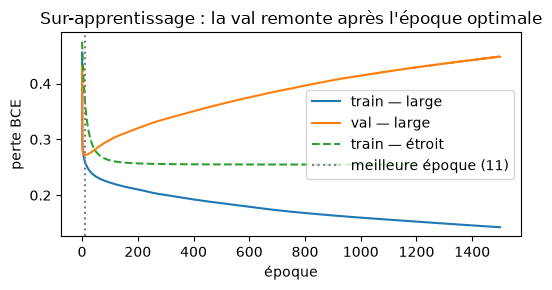

In [11]:
def make_small_blobs(seed=41, n=60, sep=1.6):
    """Tiny clean 2D dataset (small train, large clean test) for memorization demo."""
    r = np.random.default_rng(seed); nb = n // 2
    c0 = r.normal([0, 0], [1, 1], (nb, 2)); c1 = r.normal([sep, sep], [1, 1], (nb, 2))
    X = np.vstack([c0, c1]); y = np.concatenate([np.zeros(nb), np.ones(nb)])
    r2 = np.random.default_rng(seed + 7)
    c0t = r2.normal([0, 0], [1, 1], (200, 2)); c1t = r2.normal([sep, sep], [1, 1], (200, 2))
    Xte = np.vstack([c0t, c1t]); yte = np.concatenate([np.zeros(200), np.ones(200)])
    return standardize(X, Xte) + (y, yte)

def train_with_val(m, Xtr, ytr, Xva, yva, lr, epochs):
    """Full-batch training recording both losses every epoch."""
    ht, hv = [], []
    for ep in range(epochs + 1):
        ht.append(m.loss(Xtr, ytr)); hv.append(m.loss(Xva, yva))
        if ep == epochs:
            break
        dW, db = m.backward(Xtr, ytr)
        for i in range(len(m.W)):
            m.W[i] -= lr * dW[i]; m.b[i] -= lr * db[i]
    return np.array(ht), np.array(hv)

X5tr, X5te, y5tr, y5te = make_small_blobs()
net_narrow = MLP([2, 2, 1], act="relu", init="he", seed=8)
ht_narrow, hv_narrow = train_with_val(net_narrow, X5tr, y5tr, X5te, y5te, lr=0.3, epochs=1200)
net_wide = MLP([2, 64, 1], act="relu", init="he", seed=8)
ht_wide, hv_wide = train_with_val(net_wide, X5tr, y5tr, X5te, y5te, lr=0.3, epochs=1500)
ep_best = int(np.argmin(hv_wide))
print(f"étroit (h=2)  : train {ht_narrow[-1]:.3f}  val {hv_narrow[-1]:.3f}")
print(f"large  (h=64) : train {ht_wide[-1]:.3f}  val {hv_wide[-1]:.3f} (min {hv_wide.min():.3f} à l'époque {ep_best})")
print(f"-> la val du réseau large est {hv_wide[-1] / hv_wide.min():.2f}x sa meilleure valeur : OVERFITTING")

plt.figure(figsize=(5.5, 3))
plt.plot(ht_wide, label="train — large")
plt.plot(hv_wide, label="val — large")
plt.plot(ht_narrow, "--", label="train — étroit")
plt.axvline(ep_best, color="grey", ls=":", label=f"meilleure époque ({ep_best})")
plt.xlabel("époque"); plt.ylabel("perte BCE"); plt.legend()
plt.title("Sur-apprentissage : la val remonte après l'époque optimale")
plt.tight_layout(); plt.show()

### Exercice corrigé

In [12]:
# ---- Exercice P5 : le réseau large mémorise (train↓) et dégrade la val (↑) ----
assert ht_wide[-1] < 0.20                        # mémorise : sondé 0.143
assert hv_wide[-1] / hv_wide.min() > 1.4         # val dégradée de 65 % : sondé 1.65
assert ep_best < 300                             # sur-éduqué dès l'époque 11 (sondé)
assert ht_narrow[-1] > ht_wide[-1]               # l'étroit sous-apprend le train
print(f"Exercice P5 vérifié : train large {ht_wide[-1]:.3f}, val ×{hv_wide[-1]/hv_wide.min():.2f} après l'époque {ep_best}.")

Exercice P5 vérifié : train large 0.143, val ×1.65 après l'époque 11.


## 6 · Spécificités des données cyber : déséquilibre, bruit, drift

### 6a · Déséquilibre de classes
Dans un flux réel, ~95–99 % des paquets sont légitimes. Un classifieur qui dit
« bénin » tout le temps a **95 % d'exactitude** et **0 % d'utilité** : c'est le
*paradoxe de l'exactitude*.

- Métriques qui comptent : rappel sur la classe rare, AUC.
- Correctif simple : **pondération des classes** dans la BCE —
  `w₁ = n / (2·n₁)` pour les rares, `1` pour les autres.

### 6b · Labels bruités
Les tickets d'incident sont mal étiquetés (opérateur fatigué, évasion
d'attaquant). Des labels retournés à hauteur de 40 % dégradent la frontière.

### 6c · Drift de concept
Le trafic d'aujourd'hui ne ressemble pas à celui de l'entraînement (nouvelle
campagne, changement de VPN…). Un modèle figé **voit sa frontière devenir
fausse** : seule une réévaluation temporelle (et un réentraînement) le rattrape.

### Piège classique
Valider aléatoirement au lieu de **temporellement** : sur des logs, une
validation aléatoire laisse fuiter le futur dans le passé. Toujours split
chronologique dans un pipeline réel.


In [13]:
# --- (a) déséquilibre + pondération ---
def make_imbalanced(seed=51, n=2000, pos=0.05):
    """Imbalanced cyber-like dataset: 95 % benign, 5 % malicious (6 features)."""
    r = np.random.default_rng(seed); npos = int(n * pos); nneg = n - npos
    neg = r.normal(0, 1, (nneg, 6))
    posf = r.normal(0, 1, (npos, 6)) + np.array([2.0, 1.5, 0, -1.0, 0.5, 0])
    X = np.vstack([neg, posf]); y = np.concatenate([np.zeros(nneg), np.ones(npos)])
    idx = r.permutation(n); X, y = X[idx], y[idx]
    Xtr_raw, Xte_raw = X[:1500], X[1500:]
    return standardize(Xtr_raw, Xte_raw) + (y[:1500], y[1500:])

X6tr, X6te, y6tr, y6te = make_imbalanced()
net_unw = MLP([6, 32, 1], act="relu", init="he", seed=6)
net_unw.fit(X6tr, y6tr, lr=0.05, epochs=120, batch_size=64)
pred_unw = net_unw.predict(X6te)
recall_unw = float(pred_unw[y6te == 1].mean())
acc_unw = float(np.mean(pred_unw == y6te))
base_rate = float(np.mean(y6te == 0))

w_cls = np.where(y6tr == 1, len(y6tr) / (2 * y6tr.sum()), 1.0)   # w₁ = n/(2 n₁)
net_w = MLP([6, 32, 1], act="relu", init="he", seed=6)
net_w.fit(X6tr, y6tr, lr=0.05, epochs=120, batch_size=64, sample_weight=w_cls)
pred_w = net_w.predict(X6te)
recall_w = float(pred_w[y6te == 1].mean())
auc_w = roc_auc_score(y6te, net_w.forward(X6te).ravel())
print(f"taux de base (classer tout 'bénin') : {base_rate:.3f}")
print(f"sans pondération : exactitude {acc_unw:.3f} mais rappel attaques {recall_unw:.3f}  <- paradoxe")
print(f"avec pondération : rappel {recall_w:.3f}, AUC {auc_w:.3f}  <- utile")

# --- (b) labels bruités ---
def noise_case(flip, seed=61, n=400, sep=1.8):
    """2-class blobs; `flip` fraction of training labels randomly inverted."""
    r = np.random.default_rng(seed); nb = n // 2
    c0 = r.normal([0, 0], [1, 1], (nb, 2)); c1 = r.normal([sep, sep], [1, 1], (nb, 2))
    X = np.vstack([c0, c1]); y = np.concatenate([np.zeros(nb), np.ones(nb)])
    if flip > 0:
        ii = r.choice(n, int(n * flip), replace=False); y[ii] = 1 - y[ii]
    r2 = np.random.default_rng(seed + 1)
    c0t = r2.normal([0, 0], [1, 1], (300, 2)); c1t = r2.normal([sep, sep], [1, 1], (300, 2))
    Xt = np.vstack([c0t, c1t]); yt = np.concatenate([np.zeros(300), np.ones(300)])
    Xtrn, Xte = standardize(X, Xt)
    m = MLP([2, 32, 1], act="relu", init="he", seed=9)
    m.fit(Xtrn, y, lr=0.05, epochs=150, batch_size=32)
    return float(np.mean(m.predict(Xte) == yt))

acc_clean = noise_case(0.0)
acc_flip = noise_case(0.40)
print(f"labels propres : exactitude test {acc_clean:.3f}  |  40 % de labels retournés : {acc_flip:.3f}")

# --- (c) drift de concept ---
def drift_case(new_mu, seed=71, nb=500):
    """Train on source blobs, test on drifted blobs (clusters shifted toward the boundary)."""
    r = np.random.default_rng(seed)
    src = np.vstack([r.normal([0, 0], [1, 1], (nb, 2)), r.normal([3, 3], [1, 1], (nb, 2))]); ysrc = np.r_[np.zeros(nb), np.ones(nb)]
    tgt = np.vstack([r.normal(new_mu, [1, 1], (nb, 2)), r.normal(np.array(new_mu) + [3, 3], [1, 1], (nb, 2))]); ytgt = np.r_[np.zeros(nb), np.ones(nb)]
    Xs_tr, Xd_te = standardize(src[:800], tgt)
    m = MLP([2, 32, 1], act="relu", init="he", seed=9); m.fit(Xs_tr, ysrc[:800], lr=0.05, epochs=80, batch_size=32)
    src_acc = float(np.mean(m.predict(Xs_tr) == ysrc[:800])); tgt_acc = float(np.mean(m.predict(Xd_te) == ytgt))
    t2tr, t2te = standardize(tgt[:800], tgt[800:])
    m2 = MLP([2, 32, 1], act="relu", init="he", seed=9); m2.fit(t2tr, ytgt[:800], lr=0.05, epochs=80, batch_size=32)
    re_acc = float(np.mean(m2.predict(t2te) == ytgt[800:]))
    return src_acc, tgt_acc, re_acc

drift_src, drift_tgt, drift_retrain = drift_case([1.5, 1.5])
print(f"drift : exactitude source {drift_src:.3f} -> dérive {drift_tgt:.3f}  |  réentraîné sur le drift {drift_retrain:.3f}")

taux de base (classer tout 'bénin') : 0.938
sans pondération : exactitude 0.958 mais rappel attaques 0.516  <- paradoxe
avec pondération : rappel 0.645, AUC 0.940  <- utile


labels propres : exactitude test 0.907  |  40 % de labels retournés : 0.792
drift : exactitude source 0.990 -> dérive 0.753  |  réentraîné sur le drift 0.990


### Exercice corrigé

In [14]:
# ---- Exercice P6 : paradoxe de l'exactitude, bruit et drift mesurés ----
assert recall_unw < 0.60                         # sondé : 0.516 — le rappel s'effondre
assert acc_unw > recall_unw                      # paradoxe : exactitude 0.96 >> rappel 0.52
assert acc_unw >= base_rate - 0.05               # quasi aussi bien que « tout bénin »
assert recall_w >= recall_unw + 0.10             # la pondération remonte le rappel (sondé +0.13)
assert auc_w > 0.90                              # sondé : 0.94
assert acc_clean >= 0.88 and acc_flip <= 0.83    # le bruit coûte ~11 pts (sondé)
assert acc_clean - acc_flip >= 0.05
assert drift_src >= 0.95 and drift_tgt <= 0.85   # la dérive coûte ~24 pts (sondé)
assert drift_retrain >= 0.95                     # un réentraînement sur drift guérit
print(f"Exercice P6 vérifié : rappel {recall_unw:.2f}->{recall_w:.2f} (pondéré), bruit -{acc_clean-acc_flip:.2f}, drift -{drift_src-drift_tgt:.2f}.")

Exercice P6 vérifié : rappel 0.52->0.65 (pondéré), bruit -0.11, drift -0.24.


## 7 · Synthèse globale — l'essentiel & exemple intégrateur

### Ce qu'il faut retenir (les 6 points)

| # | Point | L'essentiel | Piège à ne jamais oublier |
|---|---|---|---|
| 1 | Anatomie DNN | paramètres ≈ Σ h·h′ ; mémoire ∝ batch×largeur | confondre paramètres et activations |
| 2 | Vanishing | sigmoïde : ‖∇W₁‖ ~10⁻⁶ vs sortie ~10⁻³ ; mesurer par couche | « profond = mieux » sans diagnostic |
| 3 | Exploding + clipping | ‖g‖ global > c → `g × c/‖g‖` ; borne l'amplitude, pas la direction | masquer une mauvaise init par le clipping |
| 4 | Initialisations | Xavier=tanh, He=ReLU (facteur 2) ; zéro = symétrie mortelle | init naïve σ=1 en profond (std ~10⁵) |
| 5 | Overfitting | train↓ val↑ après l'époque optimale ; capacité vs données | choisir le modèle au meilleur train |
| 6 | Données cyber | déséquilibre → rappel/AUC + pondération ; bruit ; drift → réévaluation temporelle | l'exactitude brute sur 95 % de benign |

**Exemple intégrateur** : sur une tâche de classification de flux synthétiques,
on compare **peu profond mais large** vs **profond mais étroit** — avec He+ReLU
(P4) et mini-batch (T01) — puis on mesure les normes de gradient par couche (P2)
pour valider le diagnostic sur le réseau profond.


In [15]:
def make_linear_task(seed=81):
    """Synthetic flow-like classification task (10 features, linear + noise)."""
    r7 = np.random.default_rng(seed)
    _nb = 600
    _Xa = r7.normal(0, 1, (_nb, 10)); r7.normal(0, 1, 10); r7.normal(0, 1.2, _nb)
    _Xb = r7.normal(0, 1, (400, 10)); r7.normal(0, 1, 10); r7.normal(0, 1.2, 400)
    rw = np.random.default_rng(99).normal(0, 1, 10)
    Xa = r7.normal(0, 1, (800, 10)); ya = ((Xa @ rw + r7.normal(0, 1.0, 800)) > 0).astype(float)
    Xt = r7.normal(0, 1, (400, 10)); yt = ((Xt @ rw + r7.normal(0, 1.0, 400)) > 0).astype(float)
    return Xa, ya, Xt, yt

Xa7, ya7, Xt7, yt7 = make_linear_task()
net_shallow = MLP([10, 64, 1], act="relu", init="he", seed=13)
net_shallow.fit(Xa7, ya7, lr=0.05, epochs=150, batch_size=64)
net_deep = MLP([10, 24, 24, 24, 24, 24, 1], act="relu", init="he", seed=13)
net_deep.fit(Xa7, ya7, lr=0.05, epochs=150, batch_size=64)
acc_shallow = float(np.mean(net_shallow.predict(Xt7) == yt7))
acc_deep = float(np.mean(net_deep.predict(Xt7) == yt7))
gn_deep = net_deep.grad_norms(Xa7[:64], ya7[:64])
ratio7 = gn_deep[0] / gn_deep[-2]
print(f"peu profond [10,64,1]   : exactitude test {acc_shallow:.3f}")
print(f"profond [10,24×5,1]     : exactitude test {acc_deep:.3f}")
print(f"normes de gradient du profond (entrée -> sortie) : {np.array(gn_deep)}")
print(f"-> ||∇W₁||/||∇W₅|| = {ratio7:.2f} : avec He+ReLU, pas d'effondrement (cf. P2 sigmoïde).")

peu profond [10,64,1]   : exactitude test 0.885
profond [10,24×5,1]     : exactitude test 0.865
normes de gradient du profond (entrée -> sortie) : [0.052 0.102 0.082 0.044 0.019 0.012]
-> ||∇W₁||/||∇W₅|| = 2.82 : avec He+ReLU, pas d'effondrement (cf. P2 sigmoïde).


### Exercice corrigé

In [16]:
# ---- Exercice P7 : profond bien initialisé tient tête au peu profond ----
assert acc_shallow >= 0.85                       # sondé : 0.885
assert acc_deep >= 0.80                          # sondé : 0.865
assert np.all(np.isfinite(gn_deep))              # pas d'explosion (cf. P3)
assert gn_deep[0] > 1e-3                         # la 1re couche reçoit du signal (cf. P2)
assert 0.01 < ratio7 < 100                       # chaîne de Jacobien saine
print(f"Exercice P7 vérifié : profond {acc_deep:.3f} ≈ peu profond {acc_shallow:.3f}, gradients sains (ratio {ratio7:.2f}).")

Exercice P7 vérifié : profond 0.865 ≈ peu profond 0.885, gradients sains (ratio 2.82).


In [17]:
print("NB 02 — tous les exercices sont vérifiés. ✅")

NB 02 — tous les exercices sont vérifiés. ✅
